In [22]:
from typing import Literal, Tuple
from anndata import AnnData
from tqdm.auto import tqdm
from pycirclize import Circos
from bokeh.palettes import all_palettes

import re
import os
import glob
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.colorbar as colorbar

In [23]:
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial'] # Ensure 'Arial' is in the sans-serif list

In [2]:
# fontsize
fs = 6

In [3]:
def _check_robustness_fractions(
    df_pivot, 
    threshold_qval=0.1, # adjusted p value
    threshold_valid=0.5, # fraction of results required to even consider this condition. I.e. if the test only ran for one set of thresholds, then it is not very robust.
    threshold_below_alpha=0.75, # fraction of results that need to be significant
):
    n_total = np.prod(df_pivot.shape)
    n_valid = n_total - df_pivot.isna().sum().sum()
    n_below_alpha = (df_pivot < threshold_qval).sum().sum() # number of results below pval threshold, i.e., number of significant results
    frac_valid_results = (n_valid / n_total)
    frac_pval_below_alpha = (n_below_alpha / n_valid) # fraction of significant results relative to valid results
    is_robust = (frac_pval_below_alpha > threshold_below_alpha) & (frac_valid_results > threshold_valid)
    return frac_valid_results, frac_pval_below_alpha, is_robust

def check_robustness(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(df_pivot, threshold_qval=THRESHOLD_QVAL, threshold_below_alpha=THRESHOLD_BELOW_ALPHA)
                
                if is_robust:
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results


def create_heatmap(
    all_results,
    robust_results,
    contrasts,
    celltype_combos,
    cytokines,
    figsize=None, # (2.5,4),
    path = None,
    contrast_colors = None,
    right_line_color = None,
    right_line_label = None,
    vmin=None,
    vmax=None,
):
    if figsize is None:
        figsize = (2.5,4)
    
    all_results = all_results.loc[all_results.contrast.isin(contrasts)]
    robust_results = robust_results.loc[robust_results.contrast.isin(contrasts)]

    select = (all_results.celltype_combo.isin(celltype_combos) & all_results.cytokine.isin(cytokines))
    all_results3 = all_results.loc[select].groupby(["contrast", "cytokine", "celltype_combo"])["NES"].mean().to_frame().reset_index()
    
    df_pivot = all_results3.pivot(
        index=["cytokine", "contrast"], 
        columns="celltype_combo", 
        values="NES"
    ).loc[:, celltype_combos].T

    multiindex_order = pd.MultiIndex.from_tuples(
        [(cy, c) for c in contrasts for cy in cytokines], 
        names=df_pivot.columns.names
    )
    df_pivot = df_pivot.reindex(columns=multiindex_order).T.sort_index()
    annot = df_pivot.copy().astype(str)
    
    for (_cytokine, _contrast) in df_pivot.index:
        for _celltype_combo in df_pivot.columns:
            df_selected = robust_results.loc[(robust_results.celltype_combo == _celltype_combo) & (robust_results.contrast == _contrast) & (robust_results.cytokine == _cytokine)]
            if df_selected.shape[0] == 0:
                # no robust result found
                annot.loc[((_cytokine, _contrast)), _celltype_combo] = ""
            else:
                # get alpha
                alpha = df_selected.qval_threshold.values[0]
                if alpha == 0.1:
                    annot.loc[(_cytokine, _contrast), _celltype_combo] = f"*"
                elif alpha == 0.05:
                    annot.loc[(_cytokine, _contrast), _celltype_combo] = f"**"
                elif alpha == 0.01:
                    annot.loc[(_cytokine, _contrast), _celltype_combo] = f"***"

    if vmin is None:
        vmin = df_pivot.min().min()
    else:
        assert df_pivot.min().min() >= vmin, f"{df_pivot.min().min()} vs {vmin}"
    if vmax is None:
        vmax = df_pivot.max().max()
    else:
        assert df_pivot.max().max() <= vmax, f"{df_pivot.max().max()} vs {vmax}"
    
    fig, ax = plt.subplots(1,1,figsize=figsize)
    _ax = sns.heatmap(
        df_pivot,
        square=True,
        annot=annot,
        cmap="RdBu_r",
        center=0,
        vmin=vmin,
        vmax=vmax,
        annot_kws={"fontsize": 6, "family": "Arial"},
        linecolor="white",
        fmt="",
        linewidths=0.5,
        cbar=False,
        ax=ax,
    )

    mappable = ax.collections[0]
    cmap = mappable.cmap
    norm = mappable.norm
    
    def format_cytokine_names(x):
        if isinstance(x, (list, np.ndarray)):
            return [format_cytokine_names(_x) for _x in x]
        text = x.get_text() if hasattr(x, 'get_text') else x
        text = text.replace("beta", r"$\beta$")
        text = text.replace("alpha", r"$\alpha$")
        text = text.replace("gamma", r"$\gamma$")
        text = text.replace("lambda", r"$\lambda$")
        text = text.replace("omega", r"$\omega$")
        return text

    def format_celltype_names(x):
        if isinstance(x, list):
            return [format_celltype_names(_x) for _x in x]
        text = x.get_text() if hasattr(x, 'get_text') else x
        text = text.replace("CD4-positive, alpha-beta T cell", r"CD4, $\alpha$-$\beta$ T")
        text = text.replace("CD8-positive, alpha-beta T cell", r"CD8, $\alpha$-$\beta$ T")
        text = text.replace("conventional dendritic cell", "cDC")
        text = text.replace("natural killer cell", "NK")
        if not text.startswith("NK"):
            text = text.split("(")[0]
        else:
            text = text.replace("CD56-bright_NK", "CD56hi")
            text = text.replace("CD56-dim_NK", "CD56low")
        if text.startswith("non-classical monocyte"):
            text =  "nc. Mono."
        elif text.startswith("classical monocyte"):
            text =  "c. Mono."
        return text
    
    plt.xlabel("")
    plt.ylabel("")
    ax.tick_params(axis='both', which='both', length=0)
    ax.tick_params(axis='y', which='both', pad=10)

    num_contrasts = len(all_results.contrast.unique())
    
    ytick_positions = np.arange(num_contrasts / 2, len(df_pivot.index.unique()), num_contrasts)
    ytick_labels = df_pivot.index.to_frame().cytokine.values[::num_contrasts]
    ytick_labels_reduced = format_cytokine_names(ytick_labels)
    plt.yticks(ytick_positions, ytick_labels_reduced, fontsize=fs, family="Arial")
    
    gap_positions = [0] + np.cumsum(multiindex_order.to_frame().cytokine.value_counts().values).tolist()
    xtick_positions = plt.gca().get_xticks()
    xtick_labels = plt.gca().get_xticklabels()
    xtick_labels_reduced = format_celltype_names(xtick_labels)
    
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    plt.xticks(xtick_positions, xtick_labels_reduced, fontsize=fs, family="Arial", rotation=90, ha="center")
    
    fig.canvas.draw()
    bbox = ax.get_position()
    xpos =  bbox.x0 - 0.02
    ysize = (bbox.y1 - bbox.y0) / df_pivot.shape[0]
    _df_reset = df_pivot.reset_index()
    for k in range(df_pivot.shape[0]):
        line = plt.Line2D([xpos, xpos], [bbox.y1 - k*ysize, bbox.y1 - (k+1)*ysize], transform=fig.transFigure, color=contrast_colors[_df_reset.iloc[k].contrast], linewidth=1)
        fig.lines.append(line)
        if k % num_contrasts == 0:
            line = plt.Line2D([xpos, bbox.x1], [bbox.y1 - k*ysize, bbox.y1 - k*ysize], transform=fig.transFigure, color="white", linewidth=2)
            fig.lines.append(line)
    # line at bottom
    line = plt.Line2D([xpos, bbox.x1], [bbox.y1 - (k+1)*ysize, bbox.y1 - (k+1)*ysize], transform=fig.transFigure, color="white", linewidth=2)
    fig.lines.append(line)

    if right_line_label:
        assert right_line_color is not None
        line = plt.Line2D([bbox.x1+0.02, bbox.x1+0.02], [bbox.y0, bbox.y1], transform=fig.transFigure, color=right_line_color, linewidth=1.5)
        fig.lines.append(line)
        fig.text(x=bbox.x1+0.06, y=bbox.y0 + (bbox.y1 - bbox.y0)/2, s=right_line_label, ha='center', va="center", fontsize=fs, color="black", rotation=90, fontfamily="Arial")

    if path:
        plt.savefig(
            #os.path.join(fig_path, "enichment_heatmap_lupus_vertical2_flare_vs_rest_mean.svg"), 
            path,
            bbox_inches="tight", 
            pad_inches=0, 
            dpi=500,
            transparent=True,
        )
    plt.show()
    cbar_dict = {"cmap": cmap, "norm": norm, "vmax": vmax, "vmin": vmin}
    return df_pivot, cbar_dict

In [4]:
if False:
    paths = glob.glob("./results_robustness/results_lupus_robustness_August_*.csv")
    all_results = []
    for path in paths:
        threshold_expression = float(path.split("_")[-1].split(".csv")[0])
        results = pd.read_csv(path, index_col=0)
        results.loc[:, "threshold_expression"] = threshold_expression
        all_results.append(results)
    all_results = pd.concat(all_results, axis=0, ignore_index=True)
    # all_results.to_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/all_results.csv")
else:
    all_results = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/all_results.csv")

valid_contrasts = ['managed_vs_na', 'flare_vs_na', 'treated_vs_na', 'flare_vs_managed', 'treated_vs_managed', 'flare_vs_treated']
all_results = all_results.loc[all_results.contrast.isin(valid_contrasts)]

In [5]:
all_results.percent_duplicate_ranking_stats.max()

np.float64(0.0423549343498517)

In [6]:
VMIN = -2.6
VMAX = 3

### enrichment over na (=healthy)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00,  3.08it/s]


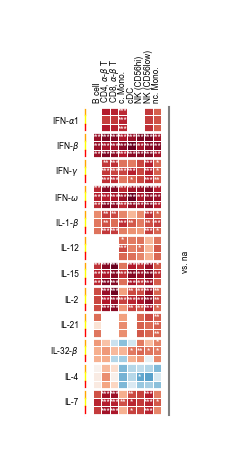

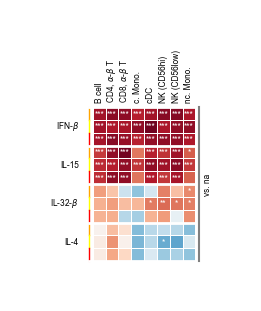

In [7]:
CONTRASTS = ['managed_vs_na', 'flare_vs_na', 'treated_vs_na']

contrast_colors = {
    'managed_vs_na': "yellow",
    'flare_vs_na': "orange",
    'treated_vs_na': "red",
}

results = all_results.loc[all_results.contrast.isin(CONTRASTS)]

robust_results_01 = check_robustness(results, THRESHOLD_QVAL=0.1, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_005 = check_robustness(results, THRESHOLD_QVAL=0.05, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_001 = check_robustness(results, THRESHOLD_QVAL=0.01, THRESHOLD_BELOW_ALPHA=0.9)
robust_results = pd.concat([robust_results_01, robust_results_005, robust_results_001])
robust_results = robust_results.groupby(["contrast", "celltype_combo", "cytokine"])["qval_threshold"].min().to_frame().reset_index()

_, cbar_dict = create_heatmap(
    results,
    robust_results,
    contrasts=CONTRASTS,
    celltype_combos=robust_results.celltype_combo.unique(),
    cytokines=robust_results.cytokine.unique(),
    figsize=(4, 4),
    contrast_colors = contrast_colors,
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/enrichment_over_na_all.svg",
    right_line_color="gray",
    right_line_label="vs. na",
)

# selected cytokines
_, cbar_dict = create_heatmap(
    results,
    robust_results,
    contrasts=CONTRASTS,
    celltype_combos=robust_results.celltype_combo.unique(),
    cytokines=["IFN-beta", "IL-15", "IL-4", "IL-32-beta"],
    figsize=(2, 2),
    contrast_colors = contrast_colors,
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/enrichment_over_na_selected.svg",
    right_line_color="gray",
    right_line_label="vs. na",
    vmin=VMIN,
    vmax=VMAX,
)

### enrichment over managed

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  4.92it/s]


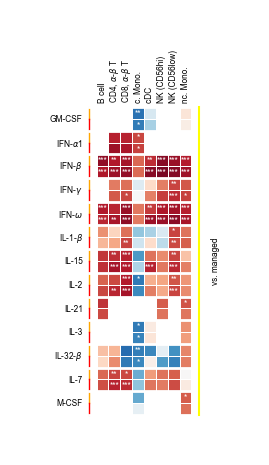

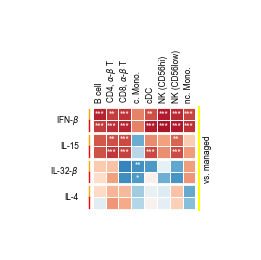

In [8]:
CONTRASTS = ['flare_vs_managed', 'treated_vs_managed']

contrast_colors = {
    'flare_vs_managed': "orange",
    'treated_vs_managed': "red",
}

results = all_results.loc[all_results.contrast.isin(CONTRASTS)]
if True:
    robust_results_01 = check_robustness(results, THRESHOLD_QVAL=0.1, THRESHOLD_BELOW_ALPHA=0.9)
    robust_results_005 = check_robustness(results, THRESHOLD_QVAL=0.05, THRESHOLD_BELOW_ALPHA=0.9)
    robust_results_001 = check_robustness(results, THRESHOLD_QVAL=0.01, THRESHOLD_BELOW_ALPHA=0.9)
    robust_results = pd.concat([robust_results_01, robust_results_005, robust_results_001])
    robust_results = robust_results.groupby(["contrast", "celltype_combo", "cytokine"])["qval_threshold"].min().to_frame().reset_index()

create_heatmap(
    results,
    robust_results,
    contrasts=CONTRASTS,
    celltype_combos=robust_results.celltype_combo.unique(),
    cytokines=robust_results.cytokine.unique(),
    figsize=(4, 4),
    contrast_colors = contrast_colors,
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/enrichment_over_managed_all.svg",
    right_line_color="yellow",
    right_line_label="vs. managed",
    vmin=VMIN,
    vmax=None,
)

# selected cytokines
_, cbar_dict = df_pivot = create_heatmap(
    results,
    robust_results,
    contrasts=CONTRASTS,
    celltype_combos=robust_results.celltype_combo.unique(),
    cytokines=["IFN-beta", "IL-15", "IL-4", "IL-32-beta"],
    figsize=(2, 2*(2/3)),
    contrast_colors = contrast_colors,
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/enrichment_over_managed_selected.svg",
    right_line_color="yellow",
    right_line_label="vs. managed",
    vmin=VMIN,
    vmax=VMAX,
)

remember_celltype_combos = robust_results.celltype_combo.unique()

### enrichment of flare over treated

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.77it/s]


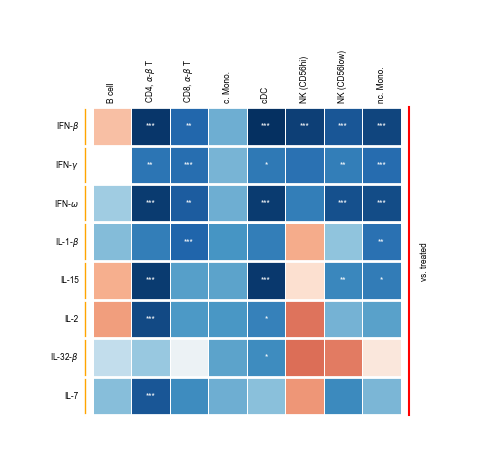

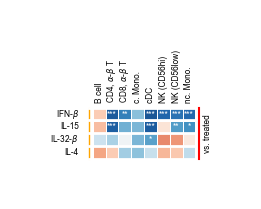

In [46]:
CONTRASTS = ['flare_vs_treated']

contrast_colors = {
    'flare_vs_treated': "orange",
}

results = all_results.loc[all_results.contrast.isin(CONTRASTS)]
robust_results_01 = check_robustness(results, THRESHOLD_QVAL=0.1, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_005 = check_robustness(results, THRESHOLD_QVAL=0.05, THRESHOLD_BELOW_ALPHA=0.9)
robust_results_001 = check_robustness(results, THRESHOLD_QVAL=0.01, THRESHOLD_BELOW_ALPHA=0.9)
robust_results = pd.concat([robust_results_01, robust_results_005, robust_results_001])
robust_results = robust_results.groupby(["contrast", "celltype_combo", "cytokine"])["qval_threshold"].min().to_frame().reset_index()

create_heatmap(
    results,
    robust_results,
    contrasts=CONTRASTS,
    celltype_combos=remember_celltype_combos,#robust_results.celltype_combo.unique(),
    cytokines=robust_results.cytokine.unique(),
    figsize=(4, 4),
    contrast_colors = contrast_colors,
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/enrichment_over_treated_all.svg",
    right_line_color="red",
    right_line_label="vs. treated",
    vmin=None,
    vmax=None,
)

# selected cytokines
_, cbar_dict = create_heatmap(
    results,
    robust_results,
    contrasts=CONTRASTS,
    celltype_combos=remember_celltype_combos,#robust_results.celltype_combo.unique(),
    cytokines=["IFN-beta", "IL-15", "IL-4", "IL-32-beta"],
    figsize=(2, 2*(1/3)),
    contrast_colors = contrast_colors,
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/enrichment_over_treated_selected.svg",
    right_line_color="red",
    right_line_label="vs. treated",
    vmin=VMIN,
    vmax=VMAX,
)

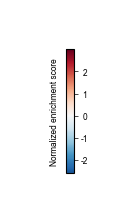

In [44]:
def custom_cmap(cmap, vmin, vmax, center):
    cmap = plt.get_cmap(cmap)
    vrange = max(vmax - center, center - vmin)
    normlize = mcolors.Normalize(center - vrange, center + vrange)
    cmin, cmax = normlize([vmin, vmax])
    cc = np.linspace(cmin, cmax, 256)
    cmap2 = mcolors.ListedColormap(cmap(cc))
    return cmap2
    
center = 0
cmap = custom_cmap("RdBu_r", vmin=VMIN, vmax=VMAX, center=center)
norm = mcolors.Normalize(vmin=VMIN, vmax=VMAX)
fig, ax = plt.subplots(figsize=(0.1, 1.605))
cbar = colorbar.ColorbarBase(
    ax,
    cmap=cmap,
    norm=norm,
    orientation='vertical',
)
# cbar.outline.set_edgecolor('white')
# cbar.outline.set_linewidth(0)
cbar.ax.set_yticks([-2, -1, 0, 1, 2])
cbar.ax.set_yticklabels(["-2", "-1", "0", "1", "2"], fontsize=fs, family="Arial", ha="center")

cbar.ax.tick_params(
    length=3,        
    width=0.5,       
    direction='out', 
    pad=5          
)
# cbar.ax.set_title("Normalized enrichment score", family="Arial", fontsize=fs, pad=5)
cbar.set_label('Normalized enrichment score', rotation=90, labelpad=5, family="Arial", fontsize=fs)

# Align the label nicely
cbar.ax.yaxis.set_label_position('left')
plt.savefig(
    "/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/colorbar.svg",
    bbox_inches="tight", 
    pad_inches=0, 
    dpi=500,
    transparent=True,
)
plt.show()

In [25]:
def create_categorical_legend_figure(
    labels_to_colors: dict,
    figsize: tuple = (5, 5),
    fontsize: int = 6,
    ncol: int = 1,
    marker_size: float = 5.,
    labelspacing: float = 0.5,
    columnspacing: float = 1.,
    handletextpad: float = 0.8,
    path: str | None = None,
):
    fig, ax = plt.subplots(figsize=figsize)
    handles = [
        mlines.Line2D([], [], color=color, marker='o', linestyle='None', markersize=marker_size, label=label)
        for label, color in labels_to_colors.items()
    ]

    # Padding to align bottom: insert empty dummy handles at beginning if uneven column lengths
    if ncol == 2:
        n_items = len(handles)
        n_rows = int(np.ceil(n_items / 2))
        col1_len = n_rows
        col2_len = n_items - col1_len
        n_spacers = col1_len - col2_len
        dummy = mlines.Line2D([], [], color='none', marker='None', linestyle='None', label='')
        for _ in range(n_spacers):
            handles.insert(col1_len, dummy)

    legend = ax.legend(
        handles=handles,
        title="",
        loc='center',
        ncol=ncol,
        fontsize=fontsize,
        frameon=False,
        labelspacing=labelspacing,
        columnspacing=columnspacing,
        handletextpad=handletextpad,
    )

    ax.set_axis_off()
    if path:
        plt.savefig(
            path, 
            bbox_inches="tight", 
            pad_inches=0, 
            dpi=500,
            transparent=True,
        )
    plt.show()

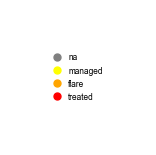

In [33]:
labels_to_colors = {"na": "gray", "managed": "yellow", "flare": "orange", "treated": "red"}

create_categorical_legend_figure(
    labels_to_colors, 
    path="/Users/soeren.becker/repos/HumanCytokineDict/notebooks/06_usecase_lupus/results_lupus/label_legend.svg",
    figsize=(0.5,0.5)
)